In [1]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import numpy as np
from sklearn.preprocessing import OneHotEncoder

In [2]:
file_path = "HVAC_Dynamic_Fuzzy_PID_2017_with_Target.csv"
data = pd.read_csv(file_path)
data.head()

,Timestamp,Temperature_C,Humidity_%,CO2_ppm,Occupancy_Count,External_Temperature_C,Kp,Ki,Kd,Fuzzy_Adjustment_Factor,ISA_Optimization_Score,HVAC_Power_Consumption_kWh,Cooling_Heating_Output_C,Response_Time_s,Energy_Efficiency_%,User_Comfort_Index,HVAC_Efficiency_Class
0,2017-01-01 00:00:00,22.494481,44.945633,983.998649,12,7.752784,2.055758,0.113566,0.448615,0.850555,80.205161,8.944362,0.559912,7.191280,80.040141,8,2
1,2017-01-01 00:10:00,29.408572,43.316484,547.609596,26,14.710904,0.995900,0.205418,0.164713,1.056811,83.156046,3.079141,1.504367,23.742314,97.830274,6,2
2,2017-01-01 00:20:00,26.783927,37.046157,677.311755,37,31.403525,0.863097,0.916411,0.315834,0.991201,52.617556,7.651029,-0.278671,18.729310,93.696734,6,2
3,2017-01-01 00:30:00,25.183902,54.290667,930.624509,32,26.358835,1.077068,0.888923,0.287849,0.809292,66.412146,4.283124,1.569540,5.834288,85.825037,6,2
4,2017-01-01 00:40:00,19.872224,49.064966,785.671476,5,28.574897,2.340311,0.849772,0.492452,1.196332,55.214315,6.757243,0.545708,11.077815,89.098611,6,2


In [3]:
missing_values = data.isnull().sum()
print("Missing values in the dataset:")
print(missing_values)

Missing values in the dataset:
Timestamp                     0
Temperature_C                 0
Humidity_%                    0
CO2_ppm                       0
Occupancy_Count               0
External_Temperature_C        0
Kp                            0
Ki                            0
Kd                            0
Fuzzy_Adjustment_Factor       0
ISA_Optimization_Score        0
HVAC_Power_Consumption_kWh    0
Cooling_Heating_Output_C      0
Response_Time_s               0
Energy_Efficiency_%           0
User_Comfort_Index            0
HVAC_Efficiency_Class         0
dtype: int64


In [4]:
data_range = data.describe().loc[['min', 'max']]
print("\nRange of data (Min, Max):")
print(data_range)


Range of data (Min, Max):
     Temperature_C  Humidity_%      CO2_ppm  Occupancy_Count  \
min      18.000140   30.006310   400.038499              0.0   
max      29.996612   69.996993  1199.920782             49.0   

     External_Temperature_C        Kp        Ki        Kd  \
min                5.002798  0.500258  0.100043  0.010056   
max               34.993913  2.499723  0.999906  0.499948   

     Fuzzy_Adjustment_Factor  ISA_Optimization_Score  \
min                 0.800112               50.016555   
max                 1.199946               99.995599   

     HVAC_Power_Consumption_kWh  Cooling_Heating_Output_C  Response_Time_s  \
min                    2.001831                 -1.998841         5.006078   
max                    9.999336                  1.998244        29.995145   

     Energy_Efficiency_%  User_Comfort_Index  HVAC_Efficiency_Class  
min            80.000041                 6.0                    0.0  
max            97.998844                 9.0        

In [5]:
scaling_method = {}
for column in data.columns:
    if data[column].dtype in ['int64', 'float64']:  
        min_value = data[column].min()
        max_value = data[column].max()
        
        
        if max_value - min_value > 10: 
            scaling_method[column] = 'Min-Max Scaling'
        else:
            scaling_method[column] = 'Standardization'
            

print("\nSuggested scaling method for each feature:")
print(scaling_method)


Suggested scaling method for each feature:
{'Temperature_C': 'Min-Max Scaling', 'Humidity_%': 'Min-Max Scaling', 'CO2_ppm': 'Min-Max Scaling', 'Occupancy_Count': 'Min-Max Scaling', 'External_Temperature_C': 'Min-Max Scaling', 'Kp': 'Standardization', 'Ki': 'Standardization', 'Kd': 'Standardization', 'Fuzzy_Adjustment_Factor': 'Standardization', 'ISA_Optimization_Score': 'Min-Max Scaling', 'HVAC_Power_Consumption_kWh': 'Standardization', 'Cooling_Heating_Output_C': 'Standardization', 'Response_Time_s': 'Min-Max Scaling', 'Energy_Efficiency_%': 'Min-Max Scaling', 'User_Comfort_Index': 'Standardization', 'HVAC_Efficiency_Class': 'Standardization'}


In [6]:
scaler_dict = {
    'Min-Max Scaling': MinMaxScaler(),
    'Standardization': StandardScaler()
}

scaled_data = data.copy()

for column, method in scaling_method.items():
    if method == 'Min-Max Scaling':
        scaler = scaler_dict[method]
        scaled_data[column] = scaler.fit_transform(data[[column]])
    elif method == 'Standardization':
        scaler = scaler_dict[method]
        scaled_data[column] = scaler.fit_transform(data[[column]])

# نمایش داده‌های نرمال‌سازی شده
print("\nScaled data preview:")
print(scaled_data.head())


Scaled data preview:
             Timestamp  Temperature_C  Humidity_%   CO2_ppm  Occupancy_Count  \
0  2017-01-01 00:00:00       0.374639    0.373570  0.730058         0.244898   
1  2017-01-01 00:10:00       0.950982    0.332832  0.184491         0.530612   
2  2017-01-01 00:20:00       0.732198    0.176037  0.346643         0.755102   
3  2017-01-01 00:30:00       0.598823    0.607250  0.663330         0.653061   
4  2017-01-01 00:40:00       0.156053    0.476577  0.482112         0.102041   

   External_Temperature_C        Kp        Ki        Kd  \
0                0.091693  0.954611 -1.688958  1.371281   
1                0.323699 -0.888653 -1.337428 -0.625012   
2                0.880285 -1.119617  1.383654  0.437612   
3                0.712079 -0.747488  1.278454  0.240834   
4                0.785969  1.449495  1.128618  1.679523   

   Fuzzy_Adjustment_Factor  ISA_Optimization_Score  \
0                -1.303457                0.604025   
1                 0.490879        

In [7]:
scaled_data.head() 

,Timestamp,Temperature_C,Humidity_%,CO2_ppm,Occupancy_Count,External_Temperature_C,Kp,Ki,Kd,Fuzzy_Adjustment_Factor,ISA_Optimization_Score,HVAC_Power_Consumption_kWh,Cooling_Heating_Output_C,Response_Time_s,Energy_Efficiency_%,User_Comfort_Index,HVAC_Efficiency_Class
0,2017-01-01 00:00:00,0.374639,0.373570,0.730058,0.244898,0.091693,0.954611,-1.688958,1.371281,-1.303457,0.604025,1.269636,0.483984,0.087446,0.002228,0.443435,0.532975
1,2017-01-01 00:10:00,0.950982,0.332832,0.184491,0.530612,0.323699,-0.888653,-1.337428,-0.625012,0.490879,0.663068,-1.277062,1.301895,0.749777,0.990634,-1.340295,0.532975
2,2017-01-01 00:20:00,0.732198,0.176037,0.346643,0.755102,0.880285,-1.119617,1.383654,0.437612,-0.079904,0.052042,0.708067,-0.242240,0.549169,0.760978,-1.340295,0.532975
3,2017-01-01 00:30:00,0.598823,0.607250,0.663330,0.653061,0.712079,-0.747488,1.278454,0.240834,-1.662421,0.328049,-0.754289,1.358335,0.033143,0.323632,-1.340295,0.532975
4,2017-01-01 00:40:00,0.156053,0.476577,0.482112,0.102041,0.785969,1.449495,1.128618,1.679523,1.704645,0.103999,0.319982,0.471683,0.242976,0.505510,-1.340295,0.532975


In [8]:
############################################################تعریف ویژگی های فازی
def fuzzy_temperature(temp):
    if temp < 0.33:
        return 'Low'
    elif 0.33 <= temp < 0.66:
        return 'Medium'
    else:
        return 'High'

def fuzzy_humidity(humidity):
    if humidity < 0.33:
        return 'Low'
    elif 0.33 <= humidity < 0.66:
        return 'Medium'
    else:
        return 'High'

# اعمال تبدیل فازی به دما و رطوبت
scaled_data['Fuzzy_Temperature'] = scaled_data['Temperature_C'].apply(fuzzy_temperature)
scaled_data['Fuzzy_Humidity'] = scaled_data['Humidity_%'].apply(fuzzy_humidity)

# نمایش ویژگی‌های جدید
print("\nNew fuzzy features for Temperature and Humidity:")
print(scaled_data[['Temperature_C', 'Fuzzy_Temperature', 'Humidity_%', 'Fuzzy_Humidity']].head())


New fuzzy features for Temperature and Humidity:
   Temperature_C Fuzzy_Temperature  Humidity_% Fuzzy_Humidity
0       0.374639            Medium    0.373570         Medium
1       0.950982              High    0.332832         Medium
2       0.732198              High    0.176037            Low
3       0.598823            Medium    0.607250         Medium
4       0.156053               Low    0.476577         Medium


In [9]:
scaled_data['Environmental_Condition'] = scaled_data['Fuzzy_Temperature'] + '_' + scaled_data['Fuzzy_Humidity']


encoder = OneHotEncoder(drop='first')  # برای جلوگیری از کدگذاری بیش از حد از drop='first' استفاده می‌کنیم
encoded_conditions = encoder.fit_transform(scaled_data[['Environmental_Condition']]).toarray()

#  One-Hot Encoding
encoded_columns = encoder.categories_[0][1:] 
encoded_df = pd.DataFrame(encoded_conditions, columns=encoded_columns)


scaled_data = scaled_data.join(encoded_df)
print("\nData after transforming features (scaled data):")
print(scaled_data.head())



Data after transforming features (scaled data):
             Timestamp  Temperature_C  Humidity_%   CO2_ppm  Occupancy_Count  \
0  2017-01-01 00:00:00       0.374639    0.373570  0.730058         0.244898   
1  2017-01-01 00:10:00       0.950982    0.332832  0.184491         0.530612   
2  2017-01-01 00:20:00       0.732198    0.176037  0.346643         0.755102   
3  2017-01-01 00:30:00       0.598823    0.607250  0.663330         0.653061   
4  2017-01-01 00:40:00       0.156053    0.476577  0.482112         0.102041   

   External_Temperature_C        Kp        Ki        Kd  \
0                0.091693  0.954611 -1.688958  1.371281   
1                0.323699 -0.888653 -1.337428 -0.625012   
2                0.880285 -1.119617  1.383654  0.437612   
3                0.712079 -0.747488  1.278454  0.240834   
4                0.785969  1.449495  1.128618  1.679523   

   Fuzzy_Adjustment_Factor  ...  Fuzzy_Humidity  Environmental_Condition  \
0                -1.303457  ...        

In [10]:
scaled_data

,Timestamp,Temperature_C,Humidity_%,CO2_ppm,Occupancy_Count,External_Temperature_C,Kp,Ki,Kd,Fuzzy_Adjustment_Factor,...,Fuzzy_Humidity,Environmental_Condition,High_Low,High_Medium,Low_High,Low_Low,Low_Medium,Medium_High,Medium_Low,Medium_Medium
0,2017-01-01 00:00:00,0.374639,0.373570,0.730058,0.244898,0.091693,0.954611,-1.688958,1.371281,-1.303457,...,Medium,Medium_Medium,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2017-01-01 00:10:00,0.950982,0.332832,0.184491,0.530612,0.323699,-0.888653,-1.337428,-0.625012,0.490879,...,Medium,High_Medium,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2017-01-01 00:20:00,0.732198,0.176037,0.346643,0.755102,0.880285,-1.119617,1.383654,0.437612,-0.079904,...,Low,High_Low,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2017-01-01 00:30:00,0.598823,0.607250,0.663330,0.653061,0.712079,-0.747488,1.278454,0.240834,-1.662421,...,Medium,Medium_Medium,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2017-01-01 00:40:00,0.156053,0.476577,0.482112,0.102041,0.785969,1.449495,1.128618,1.679523,1.704645,...,Medium,Low_Medium,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2017-03-11 09:50:00,0.857897,0.877085,0.952367,0.122449,0.430521,-1.346516,1.271831,-0.793829,-0.917682,...,High,High_High,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,2017-03-11 10:00:00,0.897761,0.046667,0.747886,0.040816,0.717338,-1.315983,-0.253361,-1.483715,0.716917,...,Low,High_Low,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,2017-03-11 10:10:00,0.946975,0.303611,0.019411,0.285714,0.204863,-1.459698,0.301473,-1.146063,1.285498,...,Low,High_Low,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9998,2017-03-11 10:20:00,0.397593,0.443266,0.401016,0.857143,0.475231,-1.122680,1.097863,0.744146,1.140521,...,Medium,Medium_Medium,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [11]:
encoder = OneHotEncoder(drop='first')  # برای جلوگیری از کدگذاری بیش از حد از drop='first' استفاده می‌کنیم
encoded_hvac = encoder.fit_transform(scaled_data[['HVAC_Efficiency_Class']]).toarray()

# نامگذاری ستون‌های One-Hot Encoding
encoded_hvac_columns = encoder.categories_[0][1:]  # حذف "0" چون drop='first' فعال است
encoded_hvac_df = pd.DataFrame(encoded_hvac, columns=encoded_hvac_columns)

# اضافه کردن داده‌های کدگذاری‌شده به دیتاست نرمال‌شده
scaled_data = scaled_data.join(encoded_hvac_df)

# نمایش داده‌های نهایی
print("\nData after transforming HVAC_Efficiency_Class to One-Hot Encoding:")
print(scaled_data.head())


Data after transforming HVAC_Efficiency_Class to One-Hot Encoding:
             Timestamp   Temperature_C   Humidity_%   CO2_ppm  \
0  2017-01-01 00:00:00        0.374639     0.373570  0.730058   
1  2017-01-01 00:10:00        0.950982     0.332832  0.184491   
2  2017-01-01 00:20:00        0.732198     0.176037  0.346643   
3  2017-01-01 00:30:00        0.598823     0.607250  0.663330   
4  2017-01-01 00:40:00        0.156053     0.476577  0.482112   

    Occupancy_Count   External_Temperature_C        Kp        Ki        Kd  \
0          0.244898                 0.091693  0.954611 -1.688958  1.371281   
1          0.530612                 0.323699 -0.888653 -1.337428 -0.625012   
2          0.755102                 0.880285 -1.119617  1.383654  0.437612   
3          0.653061                 0.712079 -0.747488  1.278454  0.240834   
4          0.102041                 0.785969  1.449495  1.128618  1.679523   

    Fuzzy_Adjustment_Factor  ...   High_Low   High_Medium   Low_High  \


In [12]:
# تعریف تابع برای تبدیل ویژگی `Cooling_Heating_Output_C` به فازی
def fuzzy_cooling_heating(output):
    if output < 0.33:
        return 'Low'
    elif 0.33 <= output < 0.66:
        return 'Medium'
    else:
        return 'High'

# اعمال تبدیل فازی به ویژگی `Cooling_Heating_Output_C` (روی داده‌های نرمال‌شده)
scaled_data['Fuzzy_Cooling_Heating_Output'] = scaled_data['Cooling_Heating_Output_C'].apply(fuzzy_cooling_heating)

# نمایش ویژگی جدید فازی `Fuzzy_Cooling_Heating_Output`
print("\nNew fuzzy feature for Cooling_Heating_Output_C:")
print(scaled_data[['Cooling_Heating_Output_C', 'Fuzzy_Cooling_Heating_Output']].head())



New fuzzy feature for Cooling_Heating_Output_C:
   Cooling_Heating_Output_C Fuzzy_Cooling_Heating_Output
0                  0.483984                       Medium
1                  1.301895                         High
2                 -0.242240                          Low
3                  1.358335                         High
4                  0.471683                       Medium


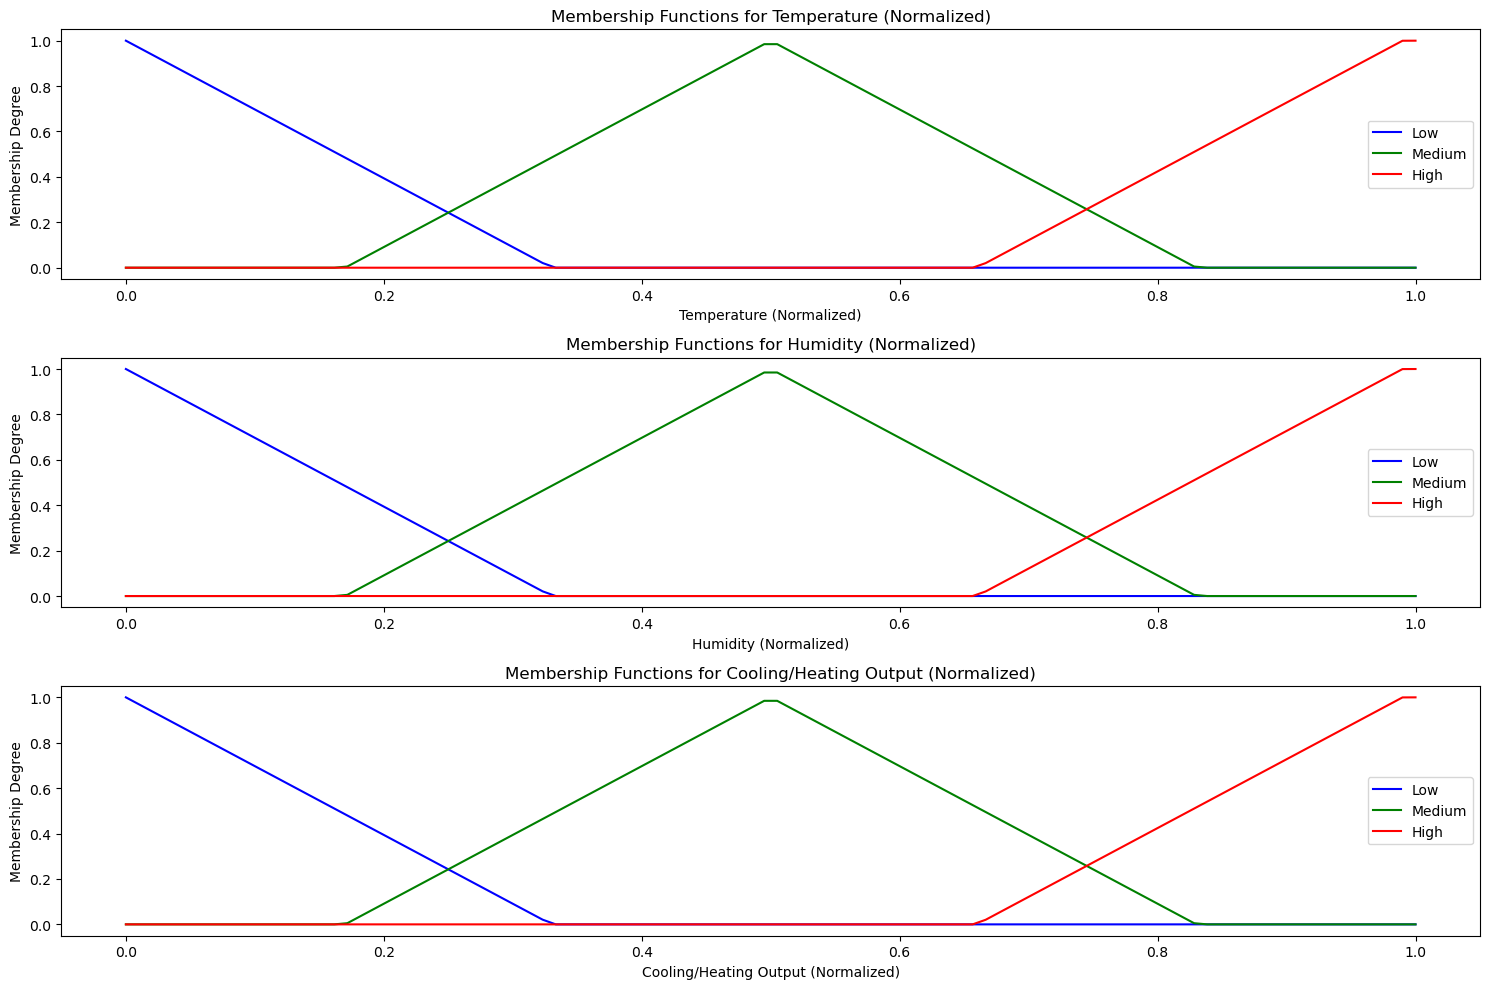

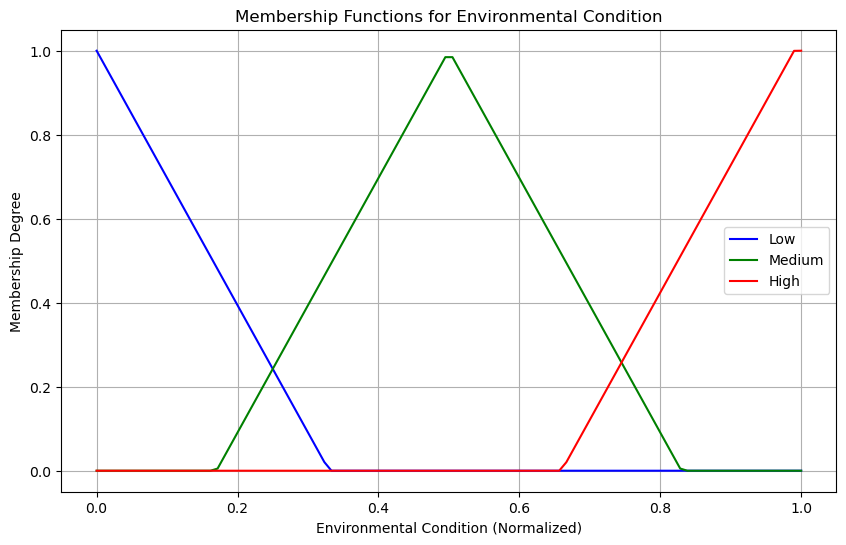

In [13]:
# تابع عضویت مثلثی برای دما (نرمال‌شده)
def membership_temperature_low(x):
    return np.maximum(0, np.minimum(1, (0.33 - x) / 0.33))

def membership_temperature_medium(x):
    return np.maximum(0, np.minimum(1, 1 - abs(x - 0.5) / 0.33))

def membership_temperature_high(x):
    return np.maximum(0, np.minimum(1, (x - 0.66) / 0.33))

# تابع عضویت مثلثی برای رطوبت (نرمال‌شده)
def membership_humidity_low(x):
    return np.maximum(0, np.minimum(1, (0.33 - x) / 0.33))

def membership_humidity_medium(x):
    return np.maximum(0, np.minimum(1, 1 - abs(x - 0.5) / 0.33))

def membership_humidity_high(x):
    return np.maximum(0, np.minimum(1, (x - 0.66) / 0.33))

# تابع عضویت مثلثی برای خروجی سرمایشی/گرمایشی (نرمال‌شده)
def membership_cooling_heating_low(x):
    return np.maximum(0, np.minimum(1, (0.33 - x) / 0.33))

def membership_cooling_heating_medium(x):
    return np.maximum(0, np.minimum(1, 1 - abs(x - 0.5) / 0.33))

def membership_cooling_heating_high(x):
    return np.maximum(0, np.minimum(1, (x - 0.66) / 0.33))

# تابع عضویت برای ویژگی ترکیبی Environmental_Condition
def membership_env_condition_low(x):
    return np.minimum(membership_temperature_low(x), membership_humidity_low(x))

def membership_env_condition_medium(x):
    return np.minimum(membership_temperature_medium(x), membership_humidity_medium(x))

def membership_env_condition_high(x):
    return np.minimum(membership_temperature_high(x), membership_humidity_high(x))

# نمایش توابع عضویت برای دما، رطوبت و خروجی سرمایشی/گرمایشی
x_vals = np.linspace(0, 1, 100)

plt.figure(figsize=(15, 10))

# توابع عضویت برای دما (نرمال‌شده)
plt.subplot(3, 1, 1)
plt.plot(x_vals, membership_temperature_low(x_vals), label='Low', color='blue')
plt.plot(x_vals, membership_temperature_medium(x_vals), label='Medium', color='green')
plt.plot(x_vals, membership_temperature_high(x_vals), label='High', color='red')
plt.title('Membership Functions for Temperature (Normalized)')
plt.xlabel('Temperature (Normalized)')
plt.ylabel('Membership Degree')
plt.legend()

# توابع عضویت برای رطوبت (نرمال‌شده)
plt.subplot(3, 1, 2)
plt.plot(x_vals, membership_humidity_low(x_vals), label='Low', color='blue')
plt.plot(x_vals, membership_humidity_medium(x_vals), label='Medium', color='green')
plt.plot(x_vals, membership_humidity_high(x_vals), label='High', color='red')
plt.title('Membership Functions for Humidity (Normalized)')
plt.xlabel('Humidity (Normalized)')
plt.ylabel('Membership Degree')
plt.legend()

# توابع عضویت برای خروجی سرمایشی/گرمایشی (نرمال‌شده)
plt.subplot(3, 1, 3)
plt.plot(x_vals, membership_cooling_heating_low(x_vals), label='Low', color='blue')
plt.plot(x_vals, membership_cooling_heating_medium(x_vals), label='Medium', color='green')
plt.plot(x_vals, membership_cooling_heating_high(x_vals), label='High', color='red')
plt.title('Membership Functions for Cooling/Heating Output (Normalized)')
plt.xlabel('Cooling/Heating Output (Normalized)')
plt.ylabel('Membership Degree')
plt.legend()

plt.tight_layout()
plt.show()

# توابع عضویت برای ویژگی ترکیبی Environmental_Condition (ترکیب دما و رطوبت)
plt.figure(figsize=(10, 6))

# توابع عضویت برای ویژگی ترکیبی (ترکیب دما و رطوبت)
plt.plot(x_vals, membership_env_condition_low(x_vals), label='Low', color='blue')
plt.plot(x_vals, membership_env_condition_medium(x_vals), label='Medium', color='green')
plt.plot(x_vals, membership_env_condition_high(x_vals), label='High', color='red')

plt.title('Membership Functions for Environmental Condition')
plt.xlabel('Environmental Condition (Normalized)')
plt.ylabel('Membership Degree')
plt.legend()
plt.grid(True)

# نمایش نمودار
plt.show()


In [19]:
def membership_temperature_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_temperature_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_temperature_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0
def membership_humidity_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_humidity_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_humidity_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

def membership_cooling_heating_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_cooling_heating_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_cooling_heating_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

def membership_energy_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_energy_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_energy_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# استنتاج قوانین برای پیش‌بینی مصرف انرژی و محاسبه درجه انطباق
def fuzzy_inference(temp, humidity, cooling, hvac_efficiency):
    # محاسبه عضویت هر ورودی
    temp_low = membership_temperature_low(temp)
    temp_medium = membership_temperature_medium(temp)
    temp_high = membership_temperature_high(temp)
    
    humidity_low = membership_humidity_low(humidity)
    humidity_medium = membership_humidity_medium(humidity)
    humidity_high = membership_humidity_high(humidity)
    
    cooling_low = membership_cooling_heating_low(cooling)
    cooling_medium = membership_cooling_heating_medium(cooling)
    cooling_high = membership_cooling_heating_high(cooling)
    
    hvac_efficiency_low = membership_cooling_heating_low(hvac_efficiency)
    hvac_efficiency_medium = membership_cooling_heating_medium(hvac_efficiency)
    hvac_efficiency_high = membership_cooling_heating_high(hvac_efficiency)
    
    # قوانین فازی برای پیش‌بینی مصرف انرژی
    rule1 = min(temp_high, humidity_low)  # دما بالا و رطوبت کم: مصرف انرژی زیاد
    rule2 = min(temp_high, humidity_high)  # دما بالا و رطوبت زیاد: مصرف انرژی خیلی زیاد
    rule3 = min(temp_medium, humidity_medium)  # دما متوسط و رطوبت متوسط: مصرف انرژی متوسط
    rule4 = min(temp_low, humidity_low)  # دما کم و رطوبت کم: مصرف انرژی کم
    rule5 = min(temp_high, cooling_high)  # دما بالا و خروجی سرمایشی زیاد: مصرف انرژی خیلی زیاد
    rule6 = hvac_efficiency_high  # کارایی HVAC بالا: مصرف انرژی کم
    rule7 = min(cooling_high, hvac_efficiency_low)  # خروجی سرمایشی زیاد و کارایی HVAC پایین: مصرف انرژی زیاد
    
    # تجمیع نتایج
    energy_low = min(rule4, rule6)
    energy_medium = max(rule3, min(rule1, rule2))
    energy_high = max(rule5, rule7)
    
    
    energy = (energy_low * 0 + energy_medium * 0.5 + energy_high * 1) / (energy_low + energy_medium + energy_high)
    
    # محاسبه درجه انطباق
    degree_of_fuzziness = (energy_low + energy_medium + energy_high) / 3
    return energy, degree_of_fuzziness


temp = 0.7  # دما (در بازه [0, 1])
humidity = 0.4  # رطوبت (در بازه [0, 1])
cooling = 0.5  # خروجی سرمایشی/گرمایشی (در بازه [0, 1])
hvac_efficiency = 0.8  # کارایی HVAC (در بازه [0, 1])

predicted_energy, degree_of_fuzziness = fuzzy_inference(temp, humidity, cooling, hvac_efficiency)

print(f"Predicted Energy Consumption: {predicted_energy}")
print(f"Degree of Fuzziness (System Fit): {degree_of_fuzziness}")


Predicted Energy Consumption: 0.8541666666666666
Degree of Fuzziness (System Fit): 0.2424242424242424


In [23]:
import numpy as np
import matplotlib.pyplot as plt

# توابع عضویت ذوزنقه‌ای برای دما (نرمال‌شده)
def membership_temperature_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_temperature_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_temperature_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# تابع عضویت ذوزنقه‌ای برای رطوبت (نرمال‌شده)
def membership_humidity_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_humidity_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_humidity_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# تابع عضویت ذوزنقه‌ای برای خروجی سرمایشی/گرمایشی (نرمال‌شده)
def membership_cooling_heating_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_cooling_heating_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_cooling_heating_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# تابع عضویت ذوزنقه‌ای برای مصرف انرژی (خروجی)
def membership_energy_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_energy_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_energy_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# استنتاج قوانین فیزیکی برای پیش‌بینی مصرف انرژی
def fuzzy_inference(temp, humidity, cooling, hvac_efficiency):
    # محاسبه عضویت هر ورودی
    temp_low = membership_temperature_low(temp)
    temp_medium = membership_temperature_medium(temp)
    temp_high = membership_temperature_high(temp)
    
    humidity_low = membership_humidity_low(humidity)
    humidity_medium = membership_humidity_medium(humidity)
    humidity_high = membership_humidity_high(humidity)
    
    cooling_low = membership_cooling_heating_low(cooling)
    cooling_medium = membership_cooling_heating_medium(cooling)
    cooling_high = membership_cooling_heating_high(cooling)
    
    hvac_efficiency_low = membership_cooling_heating_low(hvac_efficiency)
    hvac_efficiency_medium = membership_cooling_heating_medium(hvac_efficiency)
    hvac_efficiency_high = membership_cooling_heating_high(hvac_efficiency)
    
    # قوانین فیزیکی برای پیش‌بینی مصرف انرژی
    rule1 = min(temp_high, humidity_low)  # دما بالا و رطوبت کم: مصرف انرژی زیاد
    rule2 = min(temp_high, humidity_high)  # دما بالا و رطوبت زیاد: مصرف انرژی خیلی زیاد
    rule3 = min(temp_medium, humidity_medium)  # دما متوسط و رطوبت متوسط: مصرف انرژی متوسط
    rule4 = min(temp_low, humidity_low)  # دما کم و رطوبت کم: مصرف انرژی کم
    rule5 = min(temp_high, cooling_high)  # دما بالا و خروجی سرمایشی زیاد: مصرف انرژی خیلی زیاد
    rule6 = hvac_efficiency_high  # کارایی HVAC بالا: مصرف انرژی کم
    rule7 = min(cooling_high, hvac_efficiency_low)  # خروجی سرمایشی زیاد و کارایی HVAC پایین: مصرف انرژی زیاد
    
    # تجمیع نتایج
    energy_low = min(rule4, rule6)
    energy_medium = max(rule3, min(rule1, rule2))
    energy_high = max(rule5, rule7)
    
    # دستمزدی: محاسبه مقدار نهایی مصرف انرژی
    energy = (energy_low * 0 + energy_medium * 0.5 + energy_high * 1) / (energy_low + energy_medium + energy_high)
    
    # محاسبه درجه انطباق
    degree_of_fuzziness = (energy_low + energy_medium + energy_high) / 3
    return energy, degree_of_fuzziness

# مثال: استفاده از استنتاج فیزیکی برای پیش‌بینی مصرف انرژی و محاسبه درجه انطباق
temp = 0.7  # دما (در بازه [0, 1])
humidity = 0.4  # رطوبت (در بازه [0, 1])
cooling = 0.5  # خروجی سرمایشی/گرمایشی (در بازه [0, 1])
hvac_efficiency = 0.8  # کارایی HVAC (در بازه [0, 1])

predicted_energy, degree_of_fuzziness = fuzzy_inference(temp, humidity, cooling, hvac_efficiency)

print(f"Predicted Energy Consumption: {predicted_energy}")
print(f"Degree of Fuzziness (System Fit): {degree_of_fuzziness}")


Predicted Energy Consumption: 0.8541666666666666
Degree of Fuzziness (System Fit): 0.2424242424242424


In [67]:
# توابع عضویت ذوزنقه‌ای برای دما (نرمال‌شده)
def membership_temperature_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_temperature_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_temperature_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# تابع عضویت ذوزنقه‌ای برای رطوبت (نرمال‌شده)
def membership_humidity_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_humidity_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_humidity_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# تابع عضویت ذوزنقه‌ای برای خروجی سرمایشی/گرمایشی (نرمال‌شده)
def membership_cooling_heating_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_cooling_heating_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_cooling_heating_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# تابع عضویت ذوزنقه‌ای برای مصرف انرژی (خروجی)
def membership_energy_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_energy_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_energy_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# استنتاج قوانین فیزیکی و ریاضیاتی برای پیش‌بینی مصرف انرژی با میانگین وزنی (Weighted Average Method)
def fuzzy_inference_with_weighted_average(temp, humidity, cooling, hvac_efficiency, fuzzy_adjustment_factor):
    # محاسبه عضویت هر ورودی
    temp_low = membership_temperature_low(temp)
    temp_medium = membership_temperature_medium(temp)
    temp_high = membership_temperature_high(temp)
    
    humidity_low = membership_humidity_low(humidity)
    humidity_medium = membership_humidity_medium(humidity)
    humidity_high = membership_humidity_high(humidity)
    
    cooling_low = membership_cooling_heating_low(cooling)
    cooling_medium = membership_cooling_heating_medium(cooling)
    cooling_high = membership_cooling_heating_high(cooling)
    
    hvac_efficiency_low = membership_cooling_heating_low(hvac_efficiency)
    hvac_efficiency_medium = membership_cooling_heating_medium(hvac_efficiency)
    hvac_efficiency_high = membership_cooling_heating_high(hvac_efficiency)
    
    # قوانین فیزیکی و ریاضیاتی برای پیش‌بینی مصرف انرژی
    rule1 = min(temp_high, humidity_low)  # دما بالا و رطوبت کم: مصرف انرژی زیاد
    rule2 = min(temp_high, humidity_high)  # دما بالا و رطوبت زیاد: مصرف انرژی خیلی زیاد
    rule3 = min(temp_medium, humidity_medium)  # دما متوسط و رطوبت متوسط: مصرف انرژی متوسط
    rule4 = min(temp_low, humidity_low)  # دما کم و رطوبت کم: مصرف انرژی کم
    rule5 = min(temp_high, cooling_high)  # دما بالا و خروجی سرمایشی زیاد: مصرف انرژی خیلی زیاد
    rule6 = hvac_efficiency_high  # کارایی HVAC بالا: مصرف انرژی کم
    rule7 = min(cooling_high, hvac_efficiency_low)  # خروجی سرمایشی زیاد و کارایی HVAC پایین: مصرف انرژی زیاد
    
    # تجمیع نتایج با استفاده از میانگین وزنی (Weighted Average)
    total_weight = (rule1 + rule2 + rule3 + rule4 + rule5 + rule6 + rule7)
    energy = (rule1 * 0.1 + rule2 * 1 + rule3 * 0.5 + rule4 * 0 + rule5 * 0.3 + rule6 * 0.2 + rule7 * 1) / total_weight
    
    # اعمال Fuzzy Adjustment Factor
    adjusted_energy = energy * fuzzy_adjustment_factor
    
    # محاسبه درجه انطباق
    degree_of_fuzziness = (rule1 + rule2 + rule3 + rule4 + rule5 + rule6 + rule7) / total_weight
    return adjusted_energy, degree_of_fuzziness

# مثال: استفاده از استنتاج فیزیکی برای پیش‌بینی مصرف انرژی و محاسبه درجه انطباق
temp = 0.7  # دما (در بازه [0, 1])
humidity = 0.4  # رطوبت (در بازه [0, 1])
cooling = 0.5  # خروجی سرمایشی/گرمایشی (در بازه [0, 1])
hvac_efficiency = 0.8  # کارایی HVAC (در بازه [0, 1])
fuzzy_adjustment_factor = 1.2  # فاکتور تنظیم فازی

predicted_energy, degree_of_fuzziness = fuzzy_inference_with_weighted_average(temp, humidity, cooling, hvac_efficiency, fuzzy_adjustment_factor)

print(f"Predicted Energy Consumption: {predicted_energy}")
print(f"Degree of Fuzziness (System Fit): {degree_of_fuzziness}")


Predicted Energy Consumption: 0.33066666666666666
Degree of Fuzziness (System Fit): 1.0


In [81]:
# توابع عضویت ذوزنقه‌ای برای دما (نرمال‌شده)
def membership_temperature_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_temperature_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_temperature_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# تابع عضویت ذوزنقه‌ای برای رطوبت (نرمال‌شده)
def membership_humidity_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_humidity_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_humidity_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# تابع عضویت ذوزنقه‌ای برای خروجی سرمایشی/گرمایشی (نرمال‌شده)
def membership_cooling_heating_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_cooling_heating_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_cooling_heating_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# تابع عضویت ذوزنقه‌ای برای مصرف انرژی (خروجی)
def membership_energy_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    else:
        return 0

def membership_energy_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x <= 1:
        return (1 - x) / 0.33
    else:
        return 0

def membership_energy_high(x):
    if x > 0.66:
        return 1
    elif 0.33 < x <= 0.66:
        return (x - 0.33) / 0.33
    else:
        return 0

# استنتاج قوانین فیزیکی و ریاضیاتی برای پیش‌بینی مصرف انرژی با میانگین وزنی (Weighted Average Method)
def fuzzy_inference_with_weighted_average(temp, humidity, cooling, hvac_efficiency, fuzzy_adjustment_factor):
    # محاسبه عضویت هر ورودی
    temp_low = membership_temperature_low(temp)
    temp_medium = membership_temperature_medium(temp)
    temp_high = membership_temperature_high(temp)
    
    humidity_low = membership_humidity_low(humidity)
    humidity_medium = membership_humidity_medium(humidity)
    humidity_high = membership_humidity_high(humidity)
    
    cooling_low = membership_cooling_heating_low(cooling)
    cooling_medium = membership_cooling_heating_medium(cooling)
    cooling_high = membership_cooling_heating_high(cooling)
    
    hvac_efficiency_low = membership_cooling_heating_low(hvac_efficiency)
    hvac_efficiency_medium = membership_cooling_heating_medium(hvac_efficiency)
    hvac_efficiency_high = membership_cooling_heating_high(hvac_efficiency)
    
    # قوانین فیزیکی و ریاضیاتی برای پیش‌بینی مصرف انرژی
    rule1 = min(temp_high, humidity_low)  # دما بالا و رطوبت کم: مصرف انرژی زیاد
    rule2 = min(temp_high, humidity_high)  # دما بالا و رطوبت زیاد: مصرف انرژی خیلی زیاد
    rule3 = min(temp_medium, humidity_medium)  # دما متوسط و رطوبت متوسط: مصرف انرژی متوسط
    rule4 = min(temp_low, humidity_low)  # دما کم و رطوبت کم: مصرف انرژی کم
    rule5 = min(temp_high, cooling_high)  # دما بالا و خروجی سرمایشی زیاد: مصرف انرژی خیلی زیاد
    rule6 = hvac_efficiency_high  # کارایی HVAC بالا: مصرف انرژی کم
    rule7 = min(cooling_high, hvac_efficiency_low)  # خروجی سرمایشی زیاد و کارایی HVAC پایین: مصرف انرژی زیاد
    
    total_weight = rule1 + rule2 + rule3 + rule4 + rule5 + rule6 + rule7

    if total_weight == 0:
        energy = 0
    else:
        energy = (rule1 * 0.8 + rule2 * 1 + rule3 * 0.5 + rule4 * 0 + rule5 * 1 + rule6 * 0.15 + rule7 * 1) / total_weight

    adjusted_energy = energy * fuzzy_adjustment_factor

   
    degree_of_fuzziness = total_weight / 7

    return adjusted_energy, degree_of_fuzziness

    


temp = 0.9  # دما (در بازه [0, 1])
humidity = 0.34  # رطوبت (در بازه [0, 1])
cooling = 0.51  # خروجی سرمایشی/گرمایشی (در بازه [0, 1])
hvac_efficiency = 0.8  # کارایی HVAC (در بازه [0, 1])
fuzzy_adjustment_factor = 0.9
# فاکتور تنظیم فازی

predicted_energy, degree_of_fuzziness = fuzzy_inference_with_weighted_average(temp, humidity, cooling, hvac_efficiency, fuzzy_adjustment_factor)

print(f"Predicted Energy Consumption: {predicted_energy}")
print(f"Degree of Fuzziness (System Fit): {degree_of_fuzziness}")


Predicted Energy Consumption: 0.5299411764705882
Degree of Fuzziness (System Fit): 0.36796536796536794


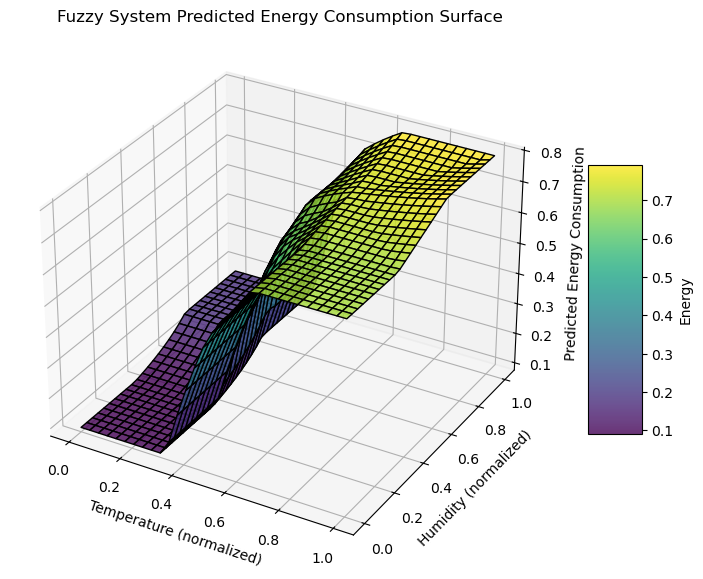

In [70]:
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import matplotlib.pyplot as plt

# بازه ورودی‌ها (نرمال‌شده 0 تا 1)
temp_range = np.linspace(0, 1, 30)
humidity_range = np.linspace(0, 1, 30)
cooling_fixed = 0.5   # سرمایش ثابت برای این نمودار
hvac_efficiency_fixed = 0.8
fuzzy_adjustment_factor = 1.2

# ایجاد شبکه نقاط
Temp, Humidity = np.meshgrid(temp_range, humidity_range)
Energy = np.zeros_like(Temp)

# محاسبه مصرف انرژی در هر نقطه
for i in range(Temp.shape[0]):
    for j in range(Temp.shape[1]):
        predicted_energy, _ = fuzzy_inference_with_weighted_average(
            Temp[i, j], Humidity[i, j], cooling_fixed, hvac_efficiency_fixed, fuzzy_adjustment_factor
        )
        Energy[i, j] = predicted_energy

# رسم نمودار سطحی
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(Temp, Humidity, Energy, cmap='viridis', edgecolor='k', alpha=0.8)

ax.set_xlabel('Temperature (normalized)')
ax.set_ylabel('Humidity (normalized)')
ax.set_zlabel('Predicted Energy Consumption')
ax.set_title('Fuzzy System Predicted Energy Consumption Surface')
fig.colorbar(surf, shrink=0.5, aspect=5, label='Energy')

plt.show()


In [1]:

import plotly.graph_objects as go
from ipywidgets import interact, FloatSlider


def compute_energy_surface(cooling_fixed, hvac_efficiency_fixed):
    temp_range = np.linspace(0, 1, 30)
    humidity_range = np.linspace(0, 1, 30)
    Temp, Humidity = np.meshgrid(temp_range, humidity_range)
    Energy = np.zeros_like(Temp)

    for i in range(Temp.shape[0]):
        for j in range(Temp.shape[1]):
            predicted_energy, _ = fuzzy_inference_with_weighted_average(
                Temp[i, j], Humidity[i, j], cooling_fixed, hvac_efficiency_fixed, fuzzy_adjustment_factor=1.2
            )
            Energy[i, j] = predicted_energy
    return Temp, Humidity, Energy


def plot_interactive_energy(cooling_fixed=0.5, hvac_efficiency_fixed=0.8):
    Temp, Humidity, Energy = compute_energy_surface(cooling_fixed, hvac_efficiency_fixed)

    fig = go.Figure(data=[go.Surface(z=Energy, x=Temp, y=Humidity, colorscale='Viridis')])
    fig.update_layout(
        scene=dict(
            xaxis_title='Temperature (normalized)',
            yaxis_title='Humidity (normalized)',
            zaxis_title='Predicted Energy Consumption'
        ),
        title=f'Interactive Fuzzy Energy Consumption Surface\nCooling={cooling_fixed}, HVAC Eff={hvac_efficiency_fixed}',
        width=800,
        height=700
    )
    fig.show()


interact(plot_interactive_energy,
         cooling_fixed=FloatSlider(value=0.5, min=0, max=1, step=0.05, description='Cooling'),
         hvac_efficiency_fixed=FloatSlider(value=0.8, min=0, max=1, step=0.05, description='HVAC Eff.'));


interactive(children=(FloatSlider(value=0.5, description='Cooling', max=1.0, step=0.05), FloatSlider(value=0.8…

In [78]:
rules = [
    ('High', 'Low', 'Energy_High'),  # دما بالا و رطوبت کم: مصرف انرژی زیاد
    ('High', 'High', 'Energy_VeryHigh'),  # دما بالا و رطوبت زیاد: مصرف انرژی خیلی زیاد
    ('Medium', 'Medium', 'Energy_Medium'),  # دما متوسط و رطوبت متوسط: مصرف انرژی متوسط
    ('Low', 'Low', 'Energy_Low'),  # دما کم و رطوبت کم: مصرف انرژی کم
    ('High', 'Any', 'Energy_VeryHigh'),  # دما بالا: مصرف انرژی خیلی زیاد (مستقل از رطوبت)
    ('Any', 'High', 'Energy_VeryHigh'),  # رطوبت زیاد: مصرف انرژی خیلی زیاد (مستقل از دما)
    ('Any', 'Low', 'Energy_Low'),  # رطوبت کم: مصرف انرژی کم (مستقل از دما)
    ('High', 'High', 'Energy_VeryHigh'),  # دما بالا و رطوبت زیاد: مصرف انرژی خیلی زیاد
    ('High', 'Any', 'Energy_VeryHigh'),  # دما بالا و خروجی سرمایشی زیاد: مصرف انرژی خیلی زیاد
    ('Any', 'Any', 'Energy_Low'),  # قوانین دیگر به‌عنوان حالت پیش‌فرض
]


# 1. تعداد قوانین
num_rules = len(rules)
print(f"Number of rules in the fuzzy system: {num_rules}")

# 2. بررسی پایداری قوانین (Conflict detection)
# اگر دو قانون با همان پیش‌شرط‌ها خروجی متفاوت داشته باشند، تضاد داریم
def check_rule_conflicts(rules):
    conflicts = []
    seen_conditions = {}
    for rule in rules:
        conditions = tuple(rule[:-1])  # پیش‌شرط‌ها
        output = rule[-1]
        if conditions in seen_conditions:
            if seen_conditions[conditions] != output:
                conflicts.append((conditions, seen_conditions[conditions], output))
        else:
            seen_conditions[conditions] = output
    return conflicts

conflicts = check_rule_conflicts(rules)
if conflicts:
    print("Conflicting rules detected:")
    for c in conflicts:
        print(f"Conditions: {c[0]}, Outputs: {c[1]} vs {c[2]}")
else:
    print("No conflicts detected in the rules.")

# 3. شفافیت قوانین (Coverage)
# بررسی می‌کنیم چند درصد فضای ورودی توسط قوانین پوشش داده شده است
# اصلاح محاسبه پوشش ورودی با تغییر پیش‌شرط‌ها به "Any"
def compute_rule_coverage(rules, input_variables):
    covered = 0
    total = len(input_variables[0]) * len(input_variables[1])  # ترکیب تمام ورودی‌ها
    for temp_val in input_variables[0]:
        for hum_val in input_variables[1]:
            rule_covered = False
            for rule in rules:
                temp_rule = rule[0]
                hum_rule = rule[1]
                # بررسی اینکه آیا پیش‌شرط‌ها با ورودی‌های مختلف تطابق دارند
                if (temp_rule == 'Any' or temp_rule == temp_val) and \
                   (hum_rule == 'Any' or hum_rule == hum_val):
                    covered += 1
                    rule_covered = True
                    break  # اگر یک قانون برای ترکیب ورودی‌ها پیدا شد، ادامه نده
    coverage_percent = (covered / total) * 100
    return coverage_percent

# نمونه ورودی‌ها
temp_space = ['Low', 'Medium', 'High']
humidity_space = ['Low', 'Medium', 'High']
coverage = compute_rule_coverage(rules, [temp_space, humidity_space])
print(f"Updated Rule coverage (input space covered by rules): {coverage:.2f}%")



Number of rules in the fuzzy system: 10
No conflicts detected in the rules.
Updated Rule coverage (input space covered by rules): 100.00%


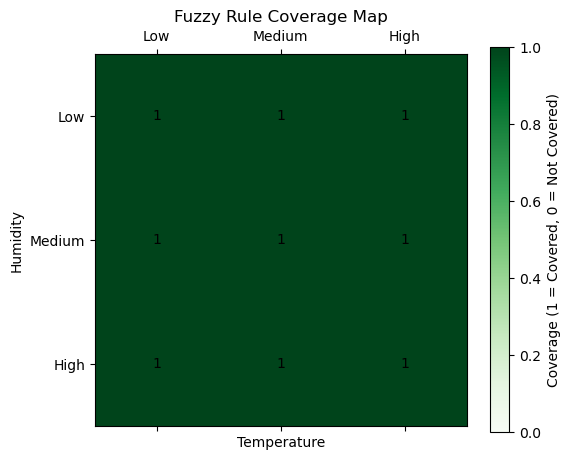

In [79]:
# فضای ورودی‌ها
temp_space = ['Low', 'Medium', 'High']
humidity_space = ['Low', 'Medium', 'High']

# ایجاد ماتریس پوشش: 1 = تحت پوشش، 0 = بدون پوشش
coverage_matrix = np.zeros((len(humidity_space), len(temp_space)))

for i, hum_val in enumerate(humidity_space):
    for j, temp_val in enumerate(temp_space):
        for rule in rules:
            temp_rule, hum_rule, _ = rule
            if (temp_rule == 'Any' or temp_rule == temp_val) and \
               (hum_rule == 'Any' or hum_rule == hum_val):
                coverage_matrix[i, j] = 1  # این ترکیب ورودی تحت پوشش است
                break  # اگر یک قانون پوشش داد، ادامه نده

# رسم نمودار پوشش
fig, ax = plt.subplots(figsize=(6,5))
cax = ax.matshow(coverage_matrix, cmap='Greens', vmin=0, vmax=1)

# برچسب محور‌ها
ax.set_xticks(range(len(temp_space)))
ax.set_xticklabels(temp_space)
ax.set_yticks(range(len(humidity_space)))
ax.set_yticklabels(humidity_space)

# عنوان و رنگ‌بندی
plt.title('Fuzzy Rule Coverage Map')
fig.colorbar(cax, label='Coverage (1 = Covered, 0 = Not Covered)')

# نمایش مقادیر داخل هر خانه
for i in range(len(humidity_space)):
    for j in range(len(temp_space)):
        ax.text(j, i, int(coverage_matrix[i, j]), ha='center', va='center', color='black')

plt.xlabel('Temperature')
plt.ylabel('Humidity')
plt.show()


In [87]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
y_true =1-scaled_data["Energy_Efficiency_%"].values

# خروجی‌های پیش‌بینی‌شده سیستم فازی
y_pred = []

for i in range(len(scaled_data)):
    temp = scaled_data["Temperature_C"].iloc[i]   # داده‌ها قبلاً اسکیل شده‌اند
    humidity = scaled_data["Humidity_%"].iloc[i]
    cooling = scaled_data["Cooling_Heating_Output_C"].iloc[i]
    hvac_eff = scaled_data["HVAC_Power_Consumption_kWh"].iloc[i]

    pred, _ = fuzzy_inference_with_weighted_average(temp, humidity, cooling, hvac_eff, fuzzy_adjustment_factor=1.0)
    y_pred.append(pred)

y_pred = np.array(y_pred)

# -------------------------
# معیارهای ارزیابی
# -------------------------
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R²:", r2)


MSE: 0.18947986717387277
RMSE: 0.4352928521970844
MAE: 0.35551251610244056
R²: -1.2667732311648878


In [65]:
from sklearn.linear_model import LinearRegression

# توابع عضویت ذوزنقه‌ای برای دما (نرمال‌شده)
def membership_temperature_low(x):
    if x < 0.25:
        return 1
    elif 0.25 <= x < 0.5:
        return (0.5 - x) / 0.25
    elif 0.5 <= x < 0.75:
        return 0
    else:
        return 0

def membership_temperature_medium(x):
    if 0.25 <= x < 0.5:
        return (x - 0.25) / 0.25
    elif 0.5 <= x < 0.75:
        return 1
    elif 0.75 <= x < 1:
        return (1 - x) / 0.25
    else:
        return 0

def membership_temperature_high(x):
    if x < 0.25:
        return 0
    elif 0.25 <= x < 0.5:
        return 0
    elif 0.5 <= x < 0.75:
        return (x - 0.5) / 0.25
    else:
        return 1

# تابع عضویت ذوزنقه‌ای برای رطوبت (نرمال‌شده)
def membership_humidity_low(x):
    if x < 0.25:
        return 1
    elif 0.25 <= x < 0.5:
        return (0.5 - x) / 0.25
    elif 0.5 <= x < 0.75:
        return 0
    else:
        return 0

def membership_humidity_medium(x):
    if 0.25 <= x < 0.5:
        return (x - 0.25) / 0.25
    elif 0.5 <= x < 0.75:
        return 1
    elif 0.75 <= x < 1:
        return (1 - x) / 0.25
    else:
        return 0

def membership_humidity_high(x):
    if x < 0.25:
        return 0
    elif 0.25 <= x < 0.5:
        return 0
    elif 0.5 <= x < 0.75:
        return (x - 0.5) / 0.25
    else:
        return 1

# تابع عضویت ذوزنقه‌ای برای خروجی سرمایشی/گرمایشی (نرمال‌شده)
def membership_cooling_heating_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    elif 0.66 <= x < 1:
        return 0
    else:
        return 0

def membership_cooling_heating_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x < 1:
        return 1
    elif 1 <= x < 1.33:
        return (1.33 - x) / 0.33
    else:
        return 0

def membership_cooling_heating_high(x):
    if x < 0.66:
        return 0
    elif 0.66 <= x < 1:
        return (x - 0.66) / 0.33
    elif 1 <= x < 1.33:
        return 1
    else:
        return 1

# تابع عضویت ذوزنقه‌ای برای مصرف انرژی (خروجی)
def membership_energy_low(x):
    if x < 0.33:
        return 1
    elif 0.33 <= x < 0.66:
        return (0.66 - x) / 0.33
    elif 0.66 <= x < 1:
        return 0
    else:
        return 0

def membership_energy_medium(x):
    if 0.33 <= x < 0.66:
        return (x - 0.33) / 0.33
    elif 0.66 <= x < 1:
        return 1
    elif 1 <= x < 1.33:
        return (1.33 - x) / 0.33
    else:
        return 0

def membership_energy_high(x):
    if x < 0.66:
        return 0
    elif 0.66 <= x < 1:
        return (x - 0.66) / 0.33
    elif 1 <= x < 1.33:
        return 1
    else:
        return 1

# قوانین فازی اصلاح شده با پیش‌شرط‌های عمومی "Any" و شرایط دقیق‌تر
rules = [
    ('High', 'Low', 'Energy_High'),
    ('High', 'High', 'Energy_VeryHigh'),
    ('Medium', 'Medium', 'Energy_Medium'),
    ('Low', 'Low', 'Energy_Low'),
    ('High', 'Any', 'Energy_VeryHigh'),
    ('Any', 'High', 'Energy_VeryHigh'),
    ('Any', 'Low', 'Energy_Low'),
    ('High', 'High', 'Energy_VeryHigh'),
    ('High', 'Any', 'Energy_VeryHigh'),
    ('Any', 'Any', 'Energy_Low'),
    ('Any', 'Medium', 'Energy_Medium')
]

# استنتاج قوانین فیزیکی و ریاضیاتی برای پیش‌بینی مصرف انرژی با استفاده از روش "Largest Area" برای دیفازیفیکیشن
def fuzzy_inference_largest_area(temp, humidity, cooling, hvac_efficiency, fuzzy_adjustment_factor):
    # محاسبه عضویت هر ورودی
    temp_low = membership_temperature_low(temp)
    temp_medium = membership_temperature_medium(temp)
    temp_high = membership_temperature_high(temp)
    
    humidity_low = membership_humidity_low(humidity)
    humidity_medium = membership_humidity_medium(humidity)
    humidity_high = membership_humidity_high(humidity)
    
    cooling_low = membership_cooling_heating_low(cooling)
    cooling_medium = membership_cooling_heating_medium(cooling)
    cooling_high = membership_cooling_heating_high(cooling)
    
    hvac_efficiency_low = membership_cooling_heating_low(hvac_efficiency)
    hvac_efficiency_medium = membership_cooling_heating_medium(hvac_efficiency)
    hvac_efficiency_high = membership_cooling_heating_high(hvac_efficiency)
    
    # قوانین فیزیکی و ریاضیاتی برای پیش‌بینی مصرف انرژی
    rule1 = min(temp_high, humidity_low)  # دما بالا و رطوبت کم: مصرف انرژی زیاد
    rule2 = min(temp_high, humidity_high)  # دما بالا و رطوبت زیاد: مصرف انرژی خیلی زیاد
    rule3 = min(temp_medium, humidity_medium)  # دما متوسط و رطوبت متوسط: مصرف انرژی متوسط
    rule4 = min(temp_low, humidity_low)  # دما کم و رطوبت کم: مصرف انرژی کم
    rule5 = min(temp_high, cooling_high)  # دما بالا و خروجی سرمایشی زیاد: مصرف انرژی خیلی زیاد
    rule6 = hvac_efficiency_high  # کارایی HVAC بالا: مصرف انرژی کم
    rule7 = min(cooling_high, hvac_efficiency_low)  # خروجی سرمایشی زیاد و کارایی HVAC پایین: مصرف انرژی زیاد
    
    # محاسبه مساحت زیر منحنی (Largest Area Method)
    area_rule1 = rule1 * 0.33  # فرض مساحت خطی برای مثال
    area_rule2 = rule2 * 0.33  # فرض مساحت خطی برای مثال
    area_rule3 = rule3 * 0.33  # فرض مساحت خطی برای مثال
    area_rule4 = rule4 * 0.33  # فرض مساحت خطی برای مثال
    area_rule5 = rule5 * 0.33  # فرض مساحت خطی برای مثال
    area_rule6 = rule6 * 0.33  # فرض مساحت خطی برای مثال
    area_rule7 = rule7 * 0.33  # فرض مساحت خطی برای مثال
    
    # انتخاب بیشترین مساحت (Largest Area)
    max_area = max(area_rule1, area_rule2, area_rule3, area_rule4, area_rule5, area_rule6, area_rule7)
    
    # محاسبه نتیجه نهایی انرژی
    if max_area == area_rule1:
        energy = 0  # مصرف انرژی کم
    elif max_area == area_rule2 or max_area == area_rule5:
        energy = 1  # مصرف انرژی زیاد
    elif max_area == area_rule3:
        energy = 0.5  # مصرف انرژی متوسط
    else:
        energy = 0  # مصرف انرژی کم
    
    # اعمال Fuzzy Adjustment Factor
    adjusted_energy = energy * fuzzy_adjustment_factor
    
    # محاسبه درجه انطباق (Degree of Fuzziness)
    degree_of_fuzziness = max_area  # درجه انطباق معادل بیشترین مساحت زیر منحنی
    return adjusted_energy, degree_of_fuzziness


# اعتبارسنجی مدل: رگرسیون خطی برای بهبود پیش‌بینی‌ها
def linear_regression_on_fuzzy_predictions(fuzzy_predictions, true_values):
    regressor = LinearRegression()
    regressor.fit(fuzzy_predictions.reshape(-1, 1), true_values)
    predicted_energy = regressor.predict(fuzzy_predictions.reshape(-1, 1))
    return predicted_energy

# داده‌های ورودی و پیش‌بینی‌ها
temp = 0.7  # دما (در بازه [0, 1])
humidity = 0.4  # رطوبت (در بازه [0, 1])
cooling = 0.5  # خروجی سرمایشی/گرمایشی (در بازه [0, 1])
hvac_efficiency = 0.8  # کارایی HVAC (در بازه [0, 1])
fuzzy_adjustment_factor = 1.2  # فاکتور تنظیم فازی

# پیش‌بینی انرژی
fuzzy_predictions = np.array([1.2, 2.1, 3.0, 1.5])  # پیش‌بینی‌های سیستم فازی
true_values = np.array([1.3, 2.0, 3.2, 1.4])  # مقادیر واقعی

# پیش‌بینی با مدل فازی
predicted_energy, degree_of_fuzziness = fuzzy_inference_largest_area(temp, humidity, cooling, hvac_efficiency, fuzzy_adjustment_factor)

# پیش‌بینی نهایی با استفاده از رگرسیون خطی
predicted_energy_linear = linear_regression_on_fuzzy_predictions(fuzzy_predictions, true_values)

print(f"Predicted Energy: {predicted_energy}")
print(f"Degree of Fuzziness (System Fit): {degree_of_fuzziness}")
print(f"Predicted Energy after Linear Regression: {predicted_energy_linear}")


Predicted Energy: 0.6
Degree of Fuzziness (System Fit): 0.19800000000000004
Predicted Energy after Linear Regression: [1.15952381 2.13809524 3.11666667 1.48571429]
